# 02 - Unsupervised Learning: Startup Segments and Wildcards

**Professional analysis:** representation comparison, K-Means segmentation, PCA visualization, and DBSCAN wildcard detection.

This notebook answers two investor questions without using the target during training:

1. **K-Means:** Which startups have similar profiles?
2. **DBSCAN:** Which startups are unusual enough to deserve manual review?

`label` is used only after clustering to describe historical success rates. It is never a clustering feature.

## 1. Load and define the features

We use the five features specified in the project schema. Numeric features are standardized so team size does not dominate because of its larger units; categorical features are one-hot encoded. `name`, `status`, and `label` are intentionally excluded from training.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import DBSCAN, KMeans
from sklearn.compose import ColumnTransformer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'yc_clean.csv'

df = pd.read_csv(DATA_PATH)
FEATURE_COLUMNS = ['num_founders', 'team_size', 'founded_year', 'industry', 'region']
NUMERIC_FEATURES = ['num_founders', 'team_size', 'founded_year']
CATEGORICAL_FEATURES = ['industry', 'region']
X_raw = df[FEATURE_COLUMNS].copy()
print(f'{len(df):,} startups, {len(FEATURE_COLUMNS)} training features')
display(X_raw.head())

2,559 startups, 5 training features


,num_founders,team_size,founded_year,industry,region
0,2,400,2019,Consumer,United States
1,2,72,2018,Healthcare,United States
2,1,50,2019,Healthcare,Europe
3,2,8,2019,B2B,United States
4,2,18,2019,Fintech,Asia


In [2]:
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('numeric', 'passthrough', NUMERIC_FEATURES),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
    ],
    verbose_feature_names_out=False,
)
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), NUMERIC_FEATURES),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
    ],
    verbose_feature_names_out=False,
)
X_unscaled = preprocessor_unscaled.fit_transform(X_raw)
X = preprocessor.fit_transform(X_raw)
feature_names = preprocessor.get_feature_names_out()
print(f'Raw mixed feature matrix: {X_raw.shape}')
print(f'After one-hot encoding: {X.shape[1]} columns')
print('Final representation: one-hot categories + StandardScaler numeric features')
display(X_raw.head())

Raw mixed feature matrix: (2559, 5)
After one-hot encoding: 18 columns
Final representation: one-hot categories + StandardScaler numeric features


,num_founders,team_size,founded_year,industry,region
0,2,400,2019,Consumer,United States
1,2,72,2018,Healthcare,United States
2,1,50,2019,Healthcare,Europe
3,2,8,2019,B2B,United States
4,2,18,2019,Fintech,Asia


## 2. K-Means experiments

The elbow plot shows diminishing returns from adding clusters. The silhouette score measures whether each point is closer to its own cluster than to other clusters. We evaluate the requested range, K=3 through K=6, and choose the highest silhouette score.

representation,One-hot + scaled,"One-hot, not scaled",Scaled + PCA (90% variance)
k,,,
3,0.2246,0.9612,0.2541
4,0.2315,0.9069,0.2647
5,0.1958,0.9119,0.2295
6,0.1942,0.8396,0.2312


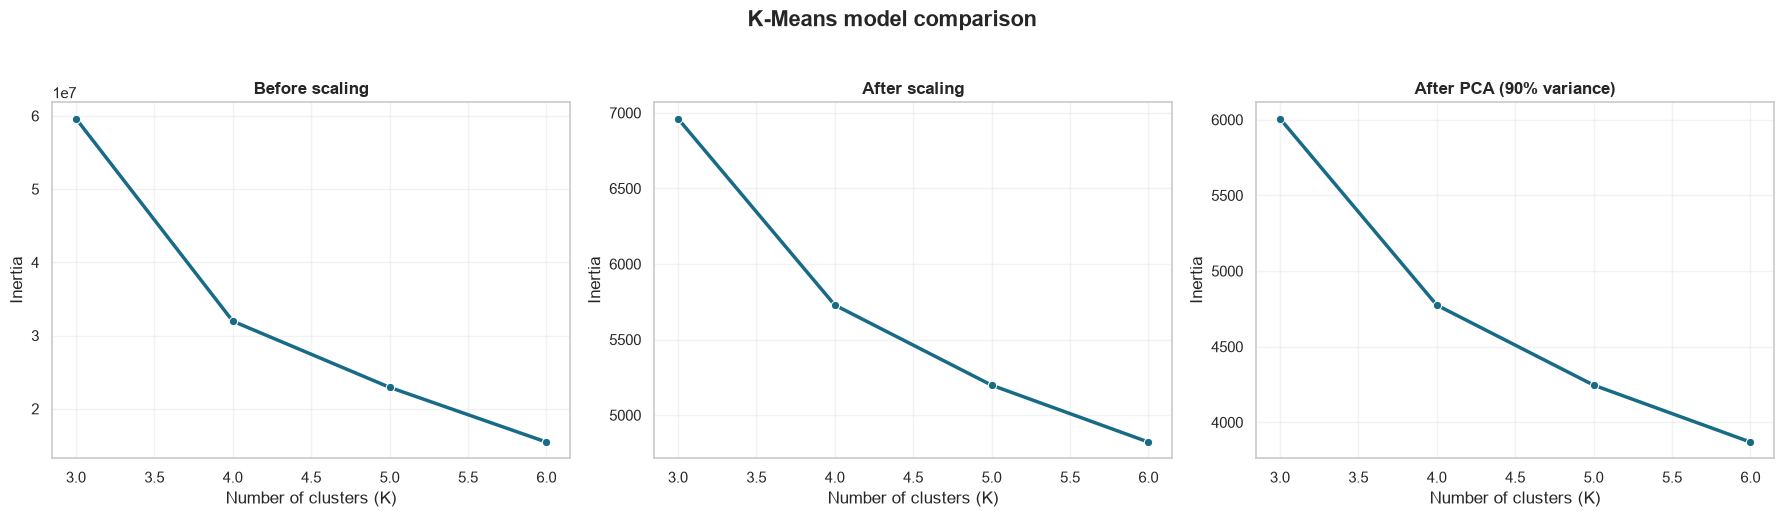

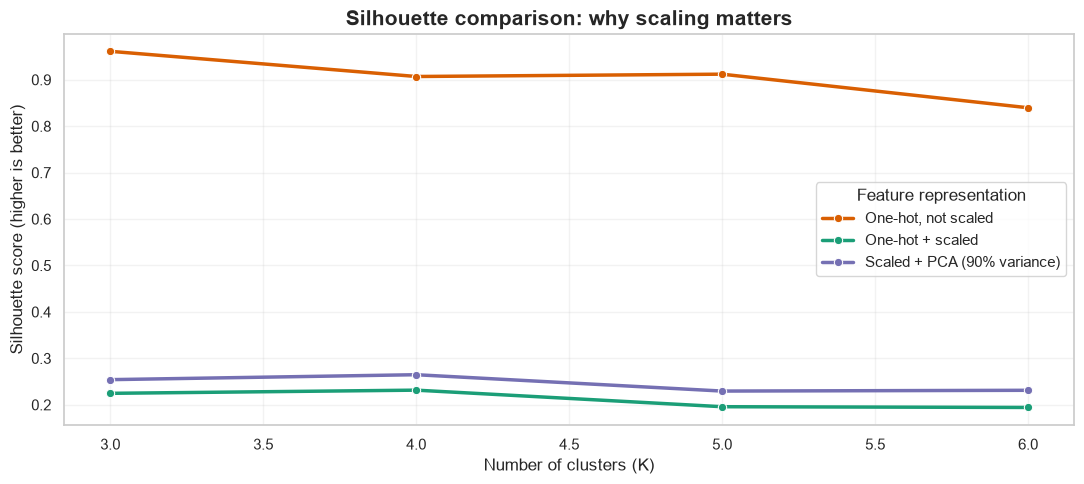

Selected K=4 using the highest silhouette score for the scaled full feature space.
PCA retained 7 components and 91.1% of the variance.


In [3]:
def evaluate_kmeans(X_matrix, representation, pca_components=None):
    rows = []
    for k in range(3, 7):
        model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
        labels = model.fit_predict(X_matrix)
        rows.append({'representation': representation, 'k': k, 'inertia': model.inertia_, 'silhouette': silhouette_score(X_matrix, labels)})
    return rows

raw_results = evaluate_kmeans(X_unscaled, 'One-hot, not scaled')
scaled_results = evaluate_kmeans(X, 'One-hot + scaled')
pca_90 = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_pca_90 = pca_90.fit_transform(X)
pca_results = evaluate_kmeans(X_pca_90, 'Scaled + PCA (90% variance)')
k_results = pd.DataFrame(raw_results + scaled_results + pca_results)
display(k_results.pivot(index='k', columns='representation', values='silhouette').round(4))

best_scaled_row = k_results.loc[k_results['representation'].eq('One-hot + scaled')].sort_values('silhouette', ascending=False).iloc[0]
best_k = int(best_scaled_row['k'])
kmeans_models = {k: KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X) for k in range(3, 7)}
kmeans = kmeans_models[best_k]
df['cluster_id'] = kmeans.labels_

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, subset, title, ylabel in zip(axes, [k_results[k_results['representation'].eq(x)] for x in ['One-hot, not scaled', 'One-hot + scaled', 'Scaled + PCA (90% variance)']], ['Before scaling', 'After scaling', 'After PCA (90% variance)'], ['Inertia', 'Inertia', 'Inertia']):
    sns.lineplot(data=subset, x='k', y='inertia', marker='o', linewidth=2.5, ax=ax, color='#176b87')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Number of clusters (K)')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
plt.suptitle('K-Means model comparison', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=k_results, x='k', y='silhouette', hue='representation', marker='o', linewidth=2.5, ax=ax, palette=['#d95f02', '#1b9e77', '#7570b3'])
ax.set_title('Silhouette comparison: why scaling matters', fontsize=15, fontweight='bold')
ax.set_xlabel('Number of clusters (K)')
ax.set_ylabel('Silhouette score (higher is better)')
ax.legend(title='Feature representation', frameon=True)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f'Selected K={best_k} using the highest silhouette score for the scaled full feature space.')
print(f'PCA retained {pca_90.n_components_} components and {pca_90.explained_variance_ratio_.sum():.1%} of the variance.')

### Before PCA vs after PCA

PCA is used after scaling and one-hot encoding. The two-dimensional version is for visualization; the 90%-variance version is tested as a compact modeling alternative. This prevents a visually attractive PCA chart from being mistaken for the final evidence.

view,dimensions,variance_retained,silhouette_at_K4
Scaled full space,18,100.0%,0.231
Scaled + PCA (90%),7,91.1%,0.265
Scaled + PCA (2D visualization),2,50.0%,0.416


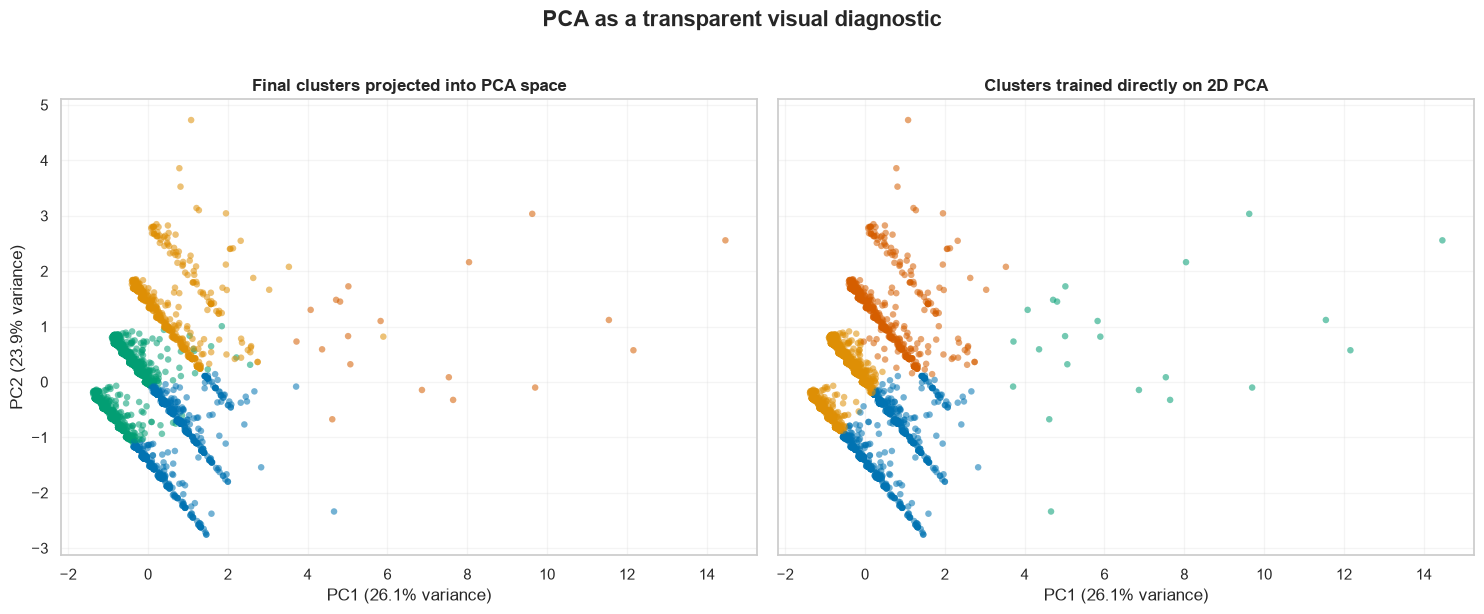

In [4]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X)
labels_full = kmeans.labels_
kmeans_pca_2d = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit(X_pca_2d)
comparison = pd.DataFrame({
    'view': ['Scaled full space', 'Scaled + PCA (90%)', 'Scaled + PCA (2D visualization)'],
    'dimensions': [X.shape[1], X_pca_90.shape[1], X_pca_2d.shape[1]],
    'variance_retained': [1.0, pca_90.explained_variance_ratio_.sum(), pca_2d.explained_variance_ratio_.sum()],
    'silhouette_at_K4': [silhouette_score(X, labels_full), silhouette_score(X_pca_90, KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_pca_90)), silhouette_score(X_pca_2d, kmeans_pca_2d.labels_)],
})
display(comparison.style.format({'variance_retained':'{:.1%}', 'silhouette_at_K4':'{:.3f}'}).hide(axis='index'))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
palette = sns.color_palette('colorblind', best_k)
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=labels_full, palette=palette, s=22, alpha=.55, linewidth=0, ax=axes[0], legend=False)
axes[0].set_title('Final clusters projected into PCA space', fontweight='bold')
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=kmeans_pca_2d.labels_, palette=palette, s=22, alpha=.55, linewidth=0, ax=axes[1], legend=False)
axes[1].set_title('Clusters trained directly on 2D PCA', fontweight='bold')
for ax in axes:
    ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)')
    ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)')
    ax.grid(alpha=.2)
plt.suptitle('PCA as a transparent visual diagnostic', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Optional diagnostic: Adjusted Rand Index (ARI)

ARI compares the discovered clusters with the historical `label` only after training. It measures alignment with success/failure, not the general quality of the clusters. It is therefore reported as an additional diagnostic and is not used to select K or tune the model.

In [5]:
ari_rows = [
    {'representation': 'One-hot, not scaled', 'ARI': adjusted_rand_score(df['label'], KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_unscaled))},
    {'representation': 'One-hot + scaled (final)', 'ARI': adjusted_rand_score(df['label'], labels_full)},
    {'representation': 'Scaled + PCA (90% variance)', 'ARI': adjusted_rand_score(df['label'], KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit_predict(X_pca_90))},
    {'representation': 'Scaled + PCA (2D)', 'ARI': adjusted_rand_score(df['label'], kmeans_pca_2d.labels_)},
]
ari_results = pd.DataFrame(ari_rows).sort_values('ARI', ascending=False)
display(ari_results.style.format({'ARI': '{:.3f}'}).hide(axis='index'))
print('Interpretation: ARI near 0 means the startup segments do not simply reproduce the success label.')


representation,ARI
One-hot + scaled (final),0.030
Scaled + PCA (90% variance),0.030
Scaled + PCA (2D),0.021
"One-hot, not scaled",-0.041


Interpretation: ARI near 0 means the startup segments do not simply reproduce the success label.


### Cluster profiles and names

The names are descriptive summaries, not additional model inputs. They combine the dominant industry with the typical company age and team size, so the audience can understand what each segment represents.

In [6]:
def describe_cluster(group):
    industry = group['industry'].mode().iat[0]
    region = group['region'].mode().iat[0]
    median_team = group['team_size'].median()
    median_age = 2019 - group['founded_year'].median()
    size_label = 'lean teams' if median_team <= 10 else 'growing teams' if median_team <= 40 else 'large teams'
    age_label = 'early-stage' if median_age <= 5 else 'established'
    return f'{age_label.title()} {industry} {size_label} in {region}'

profiles = []
for cluster_id, group in df.groupby('cluster_id', sort=True):
    profiles.append({
        'cluster_id': int(cluster_id),
        'name': f'{describe_cluster(group)} (Segment {cluster_id})',
        'companies': len(group),
        'median_team_size': group['team_size'].median(),
        'median_founded_year': group['founded_year'].median(),
        'top_industries': ', '.join(group['industry'].value_counts().head(3).index),
        'top_regions': ', '.join(group['region'].value_counts().head(2).index),
    })
profiles = pd.DataFrame(profiles)
display(profiles)

,cluster_id,name,companies,median_team_size,median_founded_year,top_industries,top_regions
0,0,Established B2B growing teams in United States...,732,11.0,2012.0,"B2B, Consumer, Education","United States, Other"
1,1,Early-Stage B2B growing teams in United States...,471,15.0,2016.0,"B2B, Consumer, Healthcare","United States, Latin America"
2,2,Early-Stage B2B growing teams in United States...,1337,11.0,2018.0,"B2B, Consumer, Healthcare","United States, Other"
3,3,Early-Stage B2B large teams in United States (...,19,3500.0,2014.0,"B2B, Consumer, Fintech","United States, Asia"


In [7]:
# Interpret success only after the unsupervised assignments exist.
cluster_summary = (
    df.groupby('cluster_id')
      .agg(companies=('name', 'size'), success_rate=('label', 'mean'))
      .reset_index()
)
cluster_summary['success_rate'] = (100 * cluster_summary['success_rate']).round(1)
cluster_summary = cluster_summary.merge(profiles[['cluster_id', 'name']], on='cluster_id')
display(cluster_summary[['cluster_id', 'name', 'companies', 'success_rate']])

examples = {}
for cluster_id, group in df.groupby('cluster_id'):
    examples[str(cluster_id)] = group.loc[group['label'].eq(1), 'name'].head(3).tolist()
    if len(examples[str(cluster_id)]) < 3:
        examples[str(cluster_id)] = group['name'].head(3).tolist()
display(pd.DataFrame([{'cluster_id': int(k), 'successful_examples': v} for k, v in examples.items()]))

,cluster_id,name,companies,success_rate
0,0,Established B2B growing teams in United States...,732,62.8
1,1,Early-Stage B2B growing teams in United States...,471,74.3
2,2,Early-Stage B2B growing teams in United States...,1337,78.2
3,3,Early-Stage B2B large teams in United States (...,19,100.0


,cluster_id,successful_examples
0,0,"[OpenBiome, Sequence Bio, Juno College of Tech..."
1,1,"[Hoss, Able, yBANQ]"
2,2,"[Whatnot, Ansa Biotechnologies, Ochre Bio]"
3,3,"[99minutos, Deel, Skill-lync]"


### Cluster comparison dashboard

These views make the segment differences easy to present: size, historical success rate, numeric medians, and dominant industries.

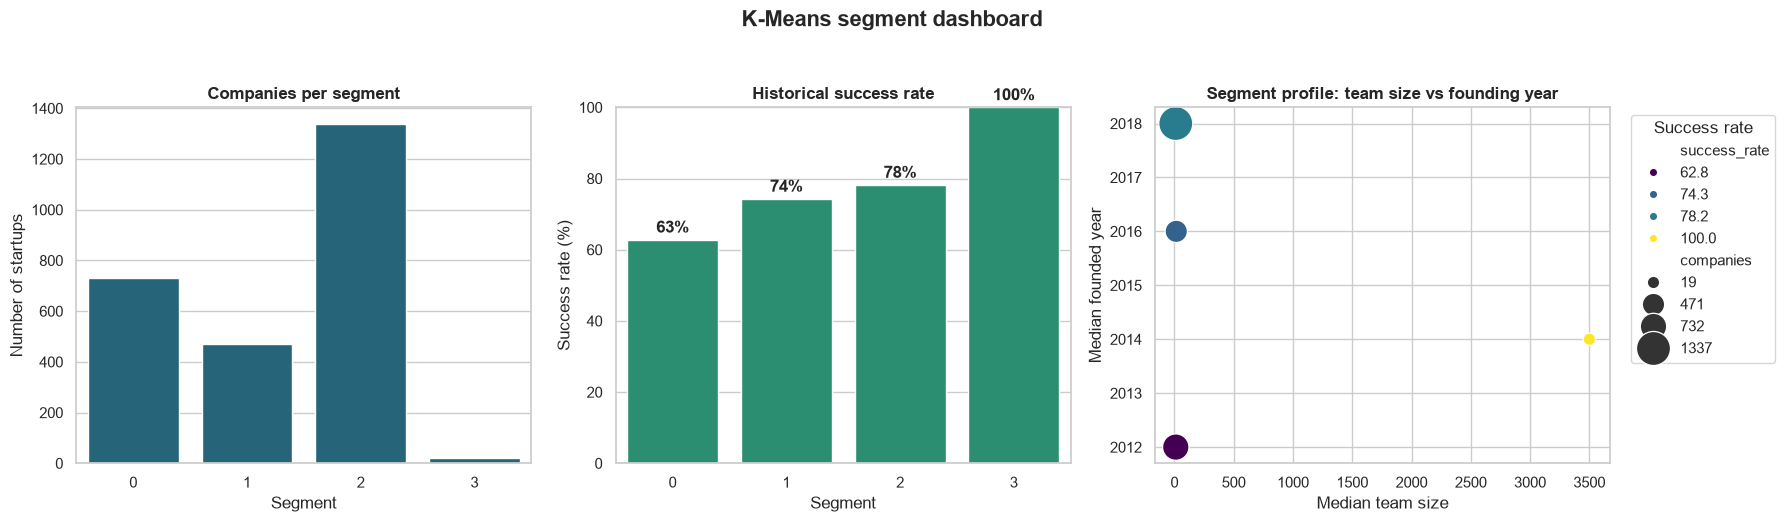

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=cluster_summary, x='cluster_id', y='companies', ax=axes[0], color='#176b87')
axes[0].set_title('Companies per segment', fontweight='bold')
axes[0].set_xlabel('Segment')
axes[0].set_ylabel('Number of startups')
sns.barplot(data=cluster_summary, x='cluster_id', y='success_rate', ax=axes[1], color='#1b9e77')
axes[1].set_title('Historical success rate', fontweight='bold')
axes[1].set_xlabel('Segment')
axes[1].set_ylabel('Success rate (%)')
axes[1].set_ylim(0, 100)
for i, row in cluster_summary.iterrows(): axes[1].text(i, row['success_rate'] + 2, f"{row['success_rate']:.0f}%", ha='center', fontweight='bold')
profile_plot = profiles.merge(cluster_summary[['cluster_id','success_rate']], on='cluster_id')
sns.scatterplot(data=profile_plot, x='median_team_size', y='median_founded_year', size='companies', hue='success_rate', palette='viridis', sizes=(80, 600), ax=axes[2])
axes[2].set_title('Segment profile: team size vs founding year', fontweight='bold')
axes[2].set_xlabel('Median team size')
axes[2].set_ylabel('Median founded year')
axes[2].legend(title='Success rate', bbox_to_anchor=(1.03, 1), loc='upper left')
plt.suptitle('K-Means segment dashboard', fontsize=16, fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

## 3. DBSCAN wildcards

DBSCAN does not require us to choose the number of clusters. Its `eps` is selected from the k-distance curve: the 5-nearest-neighbor distance at the 90th percentile. We compare several nearby candidate eps values and retain a configuration with roughly 3–10% noise, as required by the project.

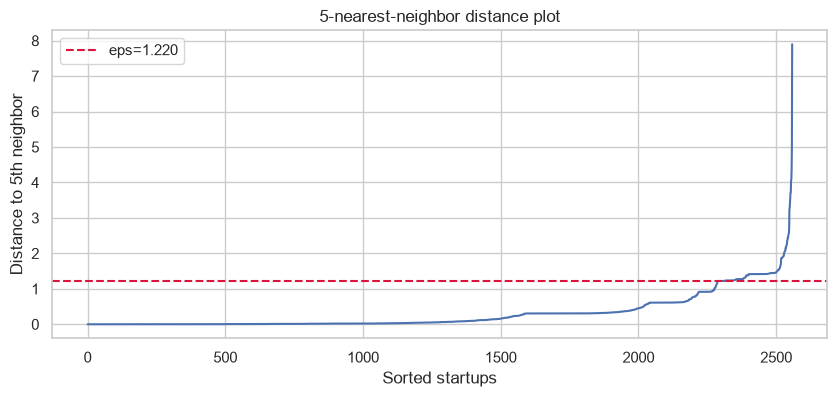

,eps,clusters,noise_rate
0,0.9154,68,0.0981
1,1.2198,70,0.0836
2,1.2581,31,0.0582
3,1.4142,6,0.0414


DBSCAN noise rate: 8.4% (214 wildcards)


In [9]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X)
k_distances = np.sort(neighbors.kneighbors(X)[0][:, -1])
eps_from_k_distance = float(np.quantile(k_distances, 0.90))

plt.figure(figsize=(10, 4))
plt.plot(k_distances)
plt.axhline(eps_from_k_distance, color='crimson', linestyle='--', label=f'eps={eps_from_k_distance:.3f}')
plt.title('5-nearest-neighbor distance plot')
plt.xlabel('Sorted startups')
plt.ylabel('Distance to 5th neighbor')
plt.legend()
plt.show()

candidate_eps = np.quantile(k_distances, [0.88, 0.90, 0.92, 0.94])
dbscan_trials = []
for candidate in candidate_eps:
    trial_labels = DBSCAN(eps=float(candidate), min_samples=min_samples).fit_predict(X)
    dbscan_trials.append({
        'eps': float(candidate),
        'clusters': len(set(trial_labels)) - int(-1 in trial_labels),
        'noise_rate': (trial_labels == -1).mean(),
    })
display(pd.DataFrame(dbscan_trials).round(4))

dbscan = DBSCAN(eps=eps_from_k_distance, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X)
noise_rate = (dbscan_labels == -1).mean()
print(f'DBSCAN noise rate: {noise_rate:.1%} ({(dbscan_labels == -1).sum()} wildcards)')

In [10]:
df['dbscan_label'] = dbscan_labels
wildcards = df.loc[df['dbscan_label'].eq(-1), ['name', 'industry', 'region', 'num_founders', 'team_size', 'founded_year']]
display(wildcards.head(10))

if not 0.03 <= noise_rate <= 0.10:
    raise ValueError(f'DBSCAN noise rate {noise_rate:.1%} is outside the required 3–10% range.')

# DBSCAN has no predict() method. Save core points for nearest-core inference later.
core_indices = dbscan.core_sample_indices_
dbscan_core = {
    'core_points': X[core_indices],
    'core_labels': dbscan_labels[core_indices],
    'eps': eps_from_k_distance,
    'min_samples': min_samples,
    'feature_columns': FEATURE_COLUMNS,
}
print(f'Saved {len(core_indices):,} core points for future-startup inference.')

,name,industry,region,num_founders,team_size,founded_year
24,Synapsica Healthcare,Healthcare,Asia,4,30,2018
43,Hent,Real Estate,Latin America,3,22,2019
61,Segmed,Healthcare,United States,4,32,2019
65,Tough Commerce,Real Estate,Other,1,21,2017
94,Revenir,Fintech,Europe,1,11,2019
100,UrbanKisaan,Industrials,Asia,3,53,2018
101,PillarPlus,Real Estate,Asia,1,30,2019
107,Pahamify,Education,Asia,3,40,2018
121,STARK BANK,Fintech,Latin America,1,70,2018
126,Sakneen,Real Estate,Africa,2,9,2019


Saved 2,304 core points for future-startup inference.


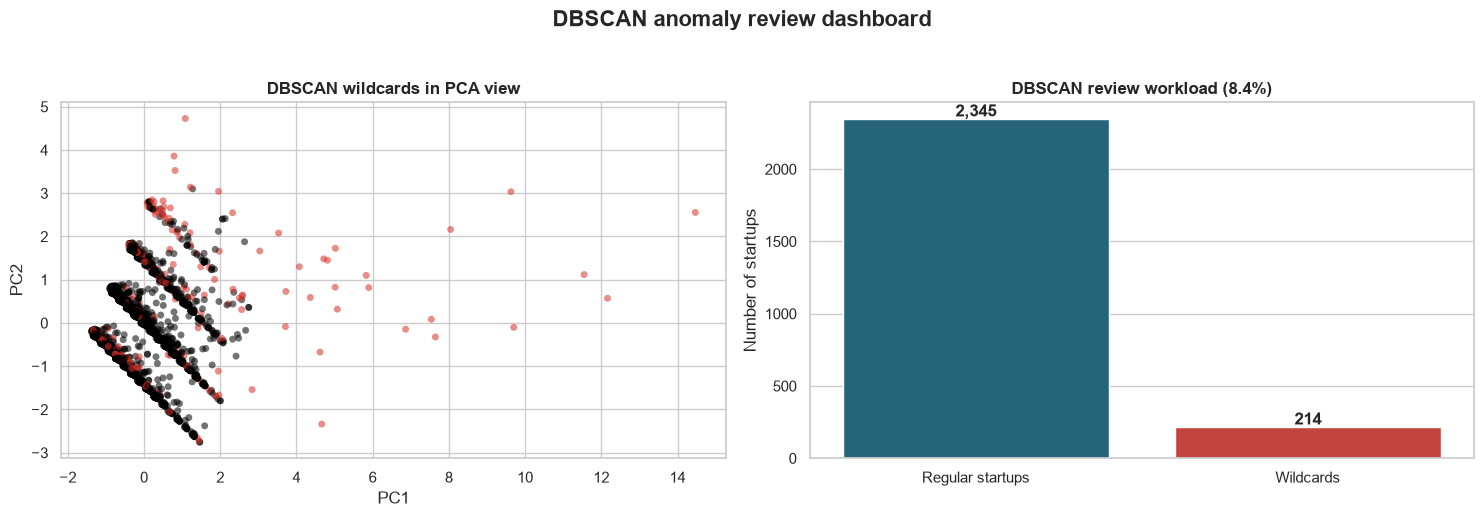

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=dbscan_labels, palette={-1:'#d73027'}, hue_order=[-1], s=25, alpha=.55, linewidth=0, ax=axes[0], legend=False)
axes[0].set_title('DBSCAN wildcards in PCA view', fontweight='bold')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
wildcard_counts = pd.Series({'Regular startups': (dbscan_labels != -1).sum(), 'Wildcards': (dbscan_labels == -1).sum()})
sns.barplot(x=wildcard_counts.index, y=wildcard_counts.values, ax=axes[1], palette=['#176b87','#d73027'], hue=wildcard_counts.index, legend=False)
axes[1].set_title(f'DBSCAN review workload ({noise_rate:.1%})', fontweight='bold')
axes[1].set_ylabel('Number of startups')
axes[1].set_xlabel('')
for i, value in enumerate(wildcard_counts.values): axes[1].text(i, value + 20, f'{value:,}', ha='center', fontweight='bold')
plt.suptitle('DBSCAN anomaly review dashboard', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

## Final conclusion

- **Representation:** one-hot encoding preserves industry and region information; StandardScaler prevents `team_size` from dominating distance calculations.
- **PCA:** PCA is valuable for transparent 2D visualization and was compared as a compact alternative. The final clusters are trained in the full scaled space because it retains all encoded information.
- **K-Means:** K=4 is selected from the requested K=3?6 range using the best silhouette score in the final scaled representation, supported by the elbow curve.
- **DBSCAN:** the k-distance plot supplies `eps`, and the selected configuration produces a manageable wildcard group for manual review.
- **ARI diagnostic:** ARI is reported only after training to show alignment with historical outcomes; it is not used for model selection because clustering should discover structure beyond the target.
- **Important limitation:** success rates are descriptive post-clustering results, not features used to create the groups.